## **Comprehensive Analysis on Brain StrokePrediction Using Machine Learning**

#  Equipe :
##### SADOG Imane
##### GHAFFARI Oualid
##### BAHAYA Radia
##### EL HADJI Oussama

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data Preprocessing
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Data Splitting and Resampling
from sklearn import model_selection
from sklearn.model_selection import cross_val_score, train_test_split, KFold
from imblearn.over_sampling import SMOTE
from collections import Counter

# Classification Models
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [ ]:
stroke_data = pd.read_csv('stroke_prediction.csv')
print ("shape of the dataset :", stroke_data.shape)
stroke_data.head()

shape of the dataset : (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
stroke_data.columns

Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

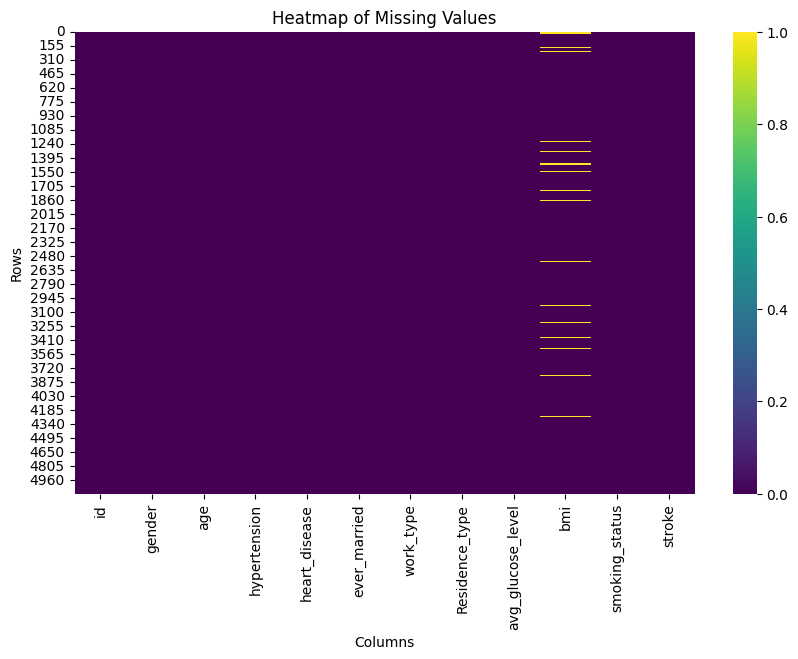

In [ ]:
# Printing the number of N/A values in each column
plt.figure(figsize=(10, 6))
sns.heatmap(stroke_data.isnull(), cbar=True, cmap='viridis')
plt.title('Heatmap of Missing Values')
plt.xlabel('Columns')
plt.ylabel('Rows')
plt.show()

print(stroke_data.isna().sum())

* Found 201 NULL values in bmi column

In [ ]:
stroke_data.describe()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [ ]:
# Provides the data type of all attributes and the number of NOT NULL values count is obtained
stroke_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
from pycaret.classification import *
import pandas as pd

# Combinaison des données équilibrées


# Configuration complète de PyCaret
clf1 = setup(
    data=stroke_data,                       # Dataset combiné
    target='stroke',                      # Nom de la colonne cible
    train_size=0.7,                       # Fraction pour l'entraînement
    session_id=123,                       # Graine aléatoire pour reproductibilité
    normalize=True,                       # Normalisation des données
    normalize_method='zscore',            # Méthode de normalisation (zscore, minmax, maxabs, robust)
    transformation=True,                  # Transformation des données
    transformation_method='yeo-johnson',  # Méthode de transformation (yeo-johnson ou quantile)
    remove_outliers=True,                 # Suppression des valeurs aberrantes
    outliers_threshold=0.05,              # Seuil pour suppression des valeurs aberrantes
    remove_multicollinearity=True,        # Suppression de la multicolinéarité
    multicollinearity_threshold=0.9,      # Seuil de corrélation pour la multicolinéarité
    polynomial_features=True,             # Création de caractéristiques polynomiales
    polynomial_degree=2,                  # Degré des caractéristiques polynomiales
    bin_numeric_features=[],              # List des colonnes numériques à transformer en catégories
    group_features=None,                  # Groupement des fonctionnalités
    pca=False,                            # Application d'une PCA
    custom_pipeline=None,                 # Pipeline de prétraitement personnalisé

)




,Description,Value
0,Session id,123
1,Target,stroke
2,Target type,Binary
3,Original data shape,"(5110, 11)"
4,Transformed data shape,"(4931, 51)"
5,Transformed train set shape,"(3398, 51)"
6,Transformed test set shape,"(1533, 51)"
7,Numeric features,10
8,Preprocess,True
9,Imputation type,simple


In [ ]:
# Comparaison des modèles
best_model = compare_models()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
dummy,Dummy Classifier,0.9514,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.6490
ridge,Ridge Classifier,0.9500,0.7895,0.0176,0.1000,0.0300,0.0249,0.0338,0.9410
knn,K Neighbors Classifier,0.9486,0.6416,0.0111,0.0833,0.0195,0.0128,0.0196,0.9590
rf,Random Forest Classifier,0.9486,0.8016,0.0114,0.1500,0.0211,0.0143,0.0299,1.5370
lr,Logistic Regression,0.9477,0.8041,0.0288,0.1233,0.0463,0.0363,0.0452,1.2870
et,Extra Trees Classifier,0.9460,0.7809,0.0402,0.1619,0.0634,0.0496,0.0621,1.2090
lightgbm,Light Gradient Boosting Machine,0.9458,0.8001,0.0520,0.2352,0.0821,0.0664,0.0875,3.3480
xgboost,Extreme Gradient Boosting,0.9421,0.7928,0.0520,0.1810,0.0769,0.0573,0.0703,1.0100
ada,Ada Boost Classifier,0.9407,0.8038,0.0915,0.2298,0.1265,0.1026,0.1158,1.3260
gbc,Gradient Boosting Classifier,0.9399,0.8183,0.0624,0.1408,0.0844,0.0612,0.0661,2.5660


Processing:   0%|          | 0/65 [00:00<?, ?it/s]

In [ ]:
# Obtenir les données prétraitées
X_preprocessed = get_config('X')  # Caractéristiques prétraitées
y_preprocessed = get_config('y')  # Colonne cible prétraitée

# Afficher les premiers enregistrements
print("X_preprocessed:")
print("\nShape:", X_preprocessed.shape)
X_preprocessed.head(10)


X_preprocessed:

Shape: (5110, 10)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
10,0,1.670617,1,0,1,2,0,-0.567981,0.108843,2
3012,0,0.255342,1,0,1,0,1,-1.099352,1.368779,3
3431,0,0.255342,0,0,1,2,0,0.030971,-0.098981,0
368,0,0.034205,0,0,1,2,0,0.027879,2.394911,2
1686,0,-1.248389,0,0,0,4,1,-0.401679,-0.956256,1
3457,0,-1.292616,0,0,0,2,1,-0.501946,-0.021047,2
2521,1,1.316798,0,1,1,2,0,-0.965294,-0.475663,3
951,1,-1.867572,0,0,0,4,0,0.376825,-1.787554,0
3154,0,0.962980,0,0,1,2,0,-0.514976,-0.137948,1
4381,0,-0.275387,0,0,0,3,1,-0.340945,2.200076,0


In [ ]:
X_preprocessed.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0


In [ ]:

print("\ny_preprocessed:")

print("\nShape:", y_preprocessed.shape)
y_preprocessed.head(1000)


y_preprocessed:

Shape: (5110,)


,stroke
10,1
3012,0
3431,0
368,0
1686,0
...,...
499,0
933,0
5072,0
3395,0


## *  **PRE PROCESSING**

In [ ]:
print ("number of duplicate rows :", stroke_data.duplicated().sum())

number of duplicate rows : 0


In [ ]:
# The 'id' column is dropped since the attribute holds no significant importance to the problem at hand
stroke_data = stroke_data.drop(['id'],axis=1)

### Gender Analysis

In [ ]:
# Checking the values in the gender column
stroke_data['gender'].value_counts()

,count
gender,
Female,2994
Male,2115
Other,1


* We have a 'Other' gender and since there is only 1 instance we will remove it as to reduce the dimension of age

<Axes: title={'center': 'Gender Count Distribution'}>

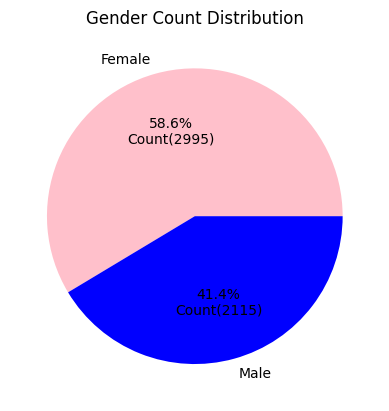

In [ ]:
# Removing the 'other' gender instance inorder to reduce the dimension
stroke_data['gender'] = stroke_data['gender'].replace('Other','Female')
# Plotting a pie chart to see the gender count distribution
stroke_data['gender'].value_counts().plot(
    kind="pie",
    title="Gender Count Distribution",
    autopct=lambda p: f'{p:.1f}%\nCount({int(p/100*stroke_data["gender"].value_counts().sum())})',
    ylabel="",  # Optional: Removes the default y-label
    colors=["pink", "blue"]
)

* There are more female as compared to males

## Target Feature - Stroke

* Stroke Feature - Stroke

In [ ]:
#Value count in the stroke attribute
stroke_data['stroke'].value_counts()

,count
stroke,
0,4861
1,249


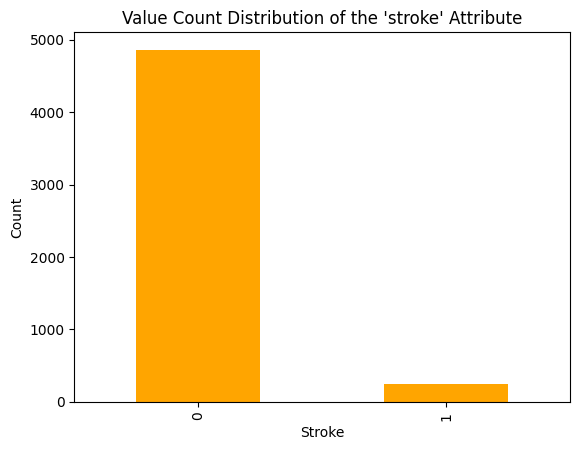

In [ ]:
# Graphical representation of the value count distribution of the target attribute
stroke_data['stroke'].value_counts().plot(
    kind="bar",
    color="orange",
    title="Value Count Distribution of the 'stroke' Attribute"
)

# Add labels and title for clarity
plt.xlabel('Stroke')
plt.ylabel('Count')
plt.title("Value Count Distribution of the 'stroke' Attribute")

# Show the plot
plt.show()

In [ ]:
print(f"Percentage of People who actuely got Stroke: {(stroke_data['stroke'].value_counts()[1]/stroke_data['stroke'].value_counts().sum()).round(3)*100}% ")

Percentage of People who actuely got Stroke: 4.9% 


* Our dataset is hightly skewed since only around 5% of the instances got stroke
* We will be needing yo perform necessary transformations to improve samples of minority class

## Hyper-Tension Analysis

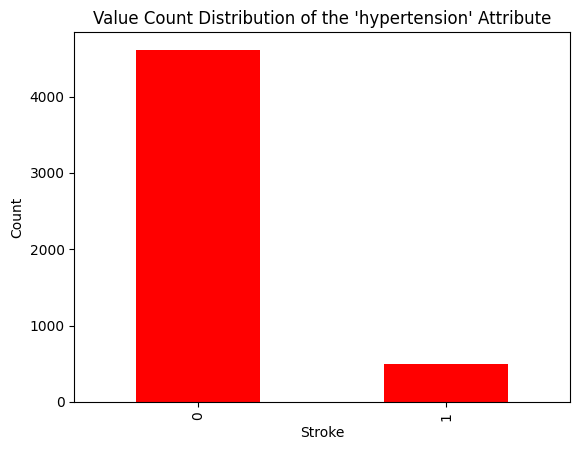

In [ ]:
# Graphical representation of the value counts of the hypertension attribute
stroke_data['hypertension'].value_counts().plot(
    kind="bar",
    color="red",
    title="Value Count Distribution of the 'stroke' Attribute"
)

# Add labels and title for clarity
plt.xlabel('Stroke')
plt.ylabel('Count')
plt.title("Value Count Distribution of the 'hypertension' Attribute")

# Show the plot
plt.show()

### Work Type Analysis

In [ ]:
# Value of count of work-type attribute
stroke_data['work_type'].value_counts()

,count
work_type,
Private,2925
Self-employed,819
children,687
Govt_job,657
Never_worked,22


<Axes: title={'center': 'Work Type Count Distribution'}>

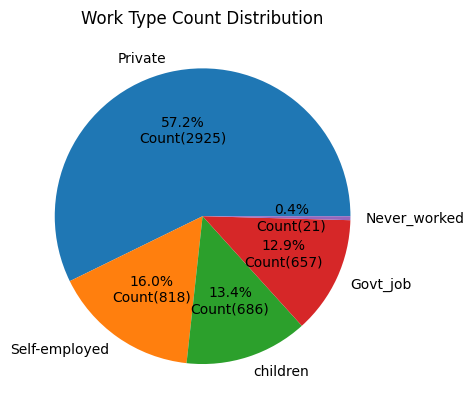

In [ ]:
stroke_data['work_type'].value_counts().plot(
    kind="pie",
    title="Work Type Count Distribution",
    autopct=lambda p: f'{p:.1f}%\nCount({int(p/100*stroke_data["gender"].value_counts().sum())})',
    ylabel="",  # Optional: Removes the default y-label
)

### Smoking Status Analysis

In [ ]:
#Value of count of smoking statuts attribute
stroke_data['smoking_status'].value_counts()

,count
smoking_status,
never smoked,1892
Unknown,1544
formerly smoked,885
smokes,789


<Axes: title={'center': 'Smoking Status Count Distribution'}>

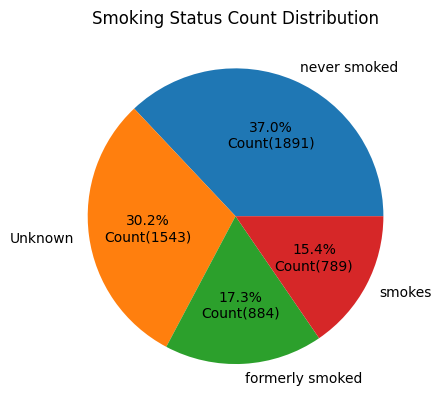

In [ ]:
#Graphical representation of thea value counts of the smoking status attribute
stroke_data['smoking_status'].value_counts().plot(
    kind="pie",
    title="Smoking Status Count Distribution",
    autopct=lambda p: f'{p:.1f}%\nCount({int(p/100*stroke_data["gender"].value_counts().sum())})',
    ylabel="",  # Optional: Removes the default y-label
)

### Residence Type Analysis

In [ ]:
# Value of count of residence attribute
stroke_data['Residence_type'].value_counts()

,count
Residence_type,
Urban,2596
Rural,2514


<Axes: title={'center': 'Residence Type Count Distribution'}>

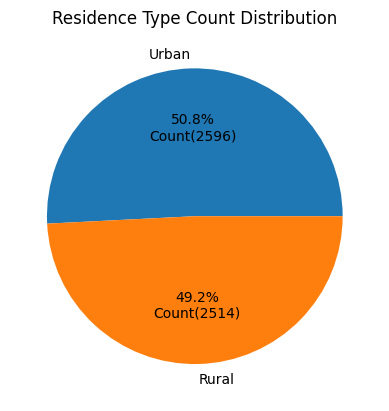

In [ ]:
# Graphic representation  of the value  counts of the residence attribute
stroke_data['Residence_type'].value_counts().plot(
    kind="pie",
    title="Residence Type Count Distribution",
    autopct=lambda p: f'{p:.1f}%\nCount({int(p/100*stroke_data["gender"].value_counts().sum())})',
    ylabel="",  # Optional: Removes the default y-label
)

* We have an equal percentage of population who are from Urban and rural areas

### BMI Analysis

In [ ]:
# Number of BMI - NULL values
stroke_data['bmi'].isnull().sum()

201

* We only have N/A values in **bmi** column - **201 Null** values

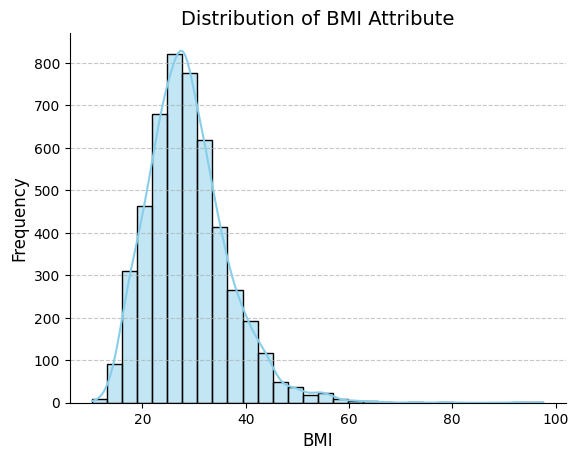

In [ ]:
# Graphical representation of bmi attribute
sns.histplot(
    data=stroke_data['bmi'],
    kde=True,  # Add a kernel density estimation curve
    bins=30,   # Set the number of bins for better granularity
    color="skyblue"  # Customize the bar color
)

# Add title and labels
plt.title("Distribution of BMI Attribute", fontsize=14)
plt.xlabel("BMI", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

# Customize the grid and style
plt.grid(axis='y', linestyle='--', alpha=0.7)
sns.despine()  # Remove top and right spines for a cleaner look

# Display the plot
plt.show()

* Bmi is rightly **skewed**

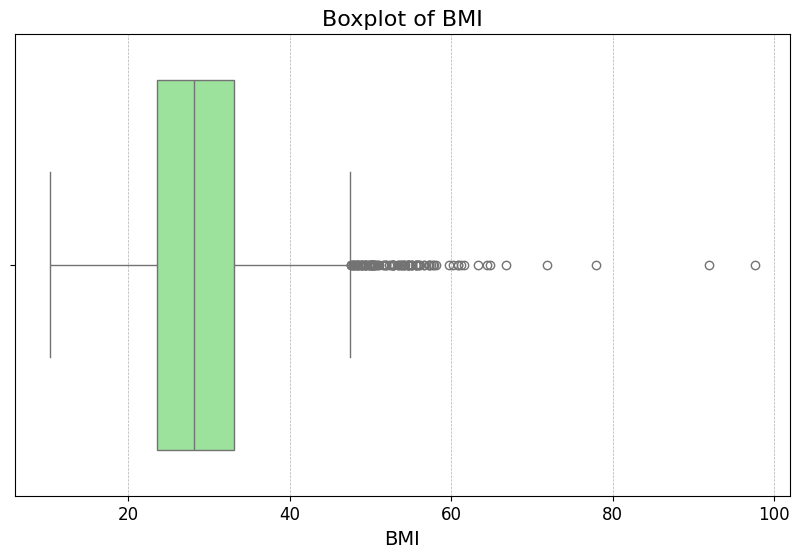

In [ ]:
# Plotting the boxplot for 'bmi'
plt.figure(figsize=(10, 6))  # Set the figure size
sns.boxplot(data=stroke_data, x='bmi', color='lightgreen')

# Customizing the plot
plt.title('Boxplot of BMI', fontsize=16)  # Add a title
plt.xlabel('BMI', fontsize=14)  # Label for the x-axis
plt.grid(True, which='both', linestyle='--', linewidth=0.5, axis='x')  # Optional grid
plt.xticks(fontsize=12)  # Customize tick size for the x-axis


plt.show()

* Based on the histogram and boxplot we see that there are many outliers in bmi

In [ ]:
# Finding the count of outliers based on those instances which are out of iqr
Q1 = stroke_data['bmi'].quantile(0.25)
Q3 = stroke_data['bmi'].quantile(0.75)
# Finding IQR
IQR = Q3 - Q1
data =(stroke_data['bmi'] < (Q1 - 1.5 * IQR)) | (stroke_data['bmi'] > (Q3 + 1.5 * IQR))
print("number of outliers in bmi columns", data.sum())

number of outliers in bmi columns 110


* Total outliers in **bmi**:  110
* Total non-outliers in **bmi**: 5000

In [ ]:
# Analysing whether to drop NA values in Bmi column
df_na = stroke_data.loc[stroke_data['bmi'].isnull()]
print("Nan BMI values where people have stroke:",df_na['stroke'].sum())
print("overall BMI values where people have stroke:",stroke_data['stroke'].sum())

Nan BMI values where people have stroke: 40
overall BMI values where people have stroke: 249


* Among the **201 BMI NULL values**, **40** of them correspond to cases with a stroke    
* Thus, we cannot drop the NULL values
* Since outliers are present, we cannot use mean imputation, as the mean is affected by outliers    
* Therefore, we will impute the missing values using the median

In [ ]:
# Imputing the missing N/A values using the median of bmi column
stroke_data['bmi'] = stroke_data['bmi'].fillna(stroke_data['bmi'].median())

### AGE Analysis

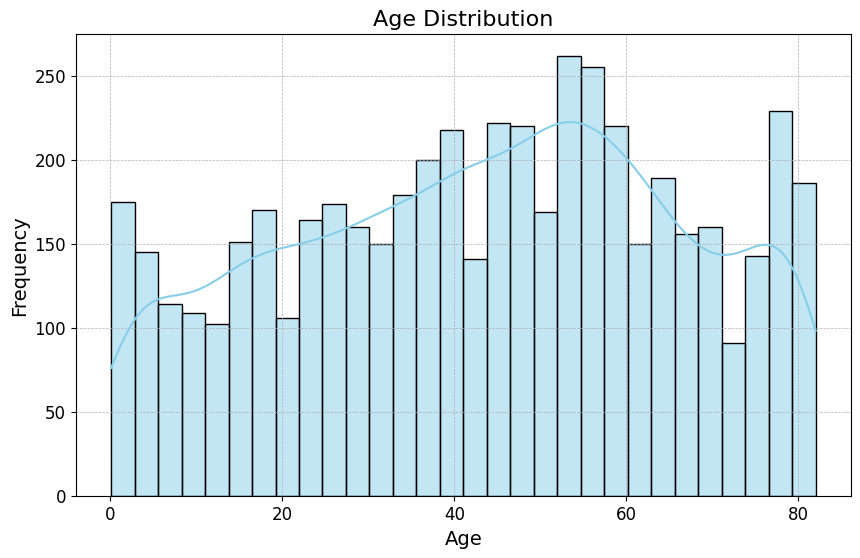

In [ ]:
# Plotting the histogram for the 'age' column
plt.figure(figsize=(10, 6))  # Set the figure size
sns.histplot(data=stroke_data, x='age', kde=True, bins=30, color='skyblue')

# Customizing the plot
plt.title('Age Distribution', fontsize=16)  # Add a title
plt.xlabel('Age', fontsize=14)  # Label for the x-axis
plt.ylabel('Frequency', fontsize=14)  # Label for the y-axis
plt.grid(True, which='both', linestyle='--', linewidth=0.5)  # Optional grid
plt.xticks(fontsize=12)  # Customize tick size for the x-axis
plt.yticks(fontsize=12)  # Customize tick size for the y-axis

# Show the plot
plt.show()


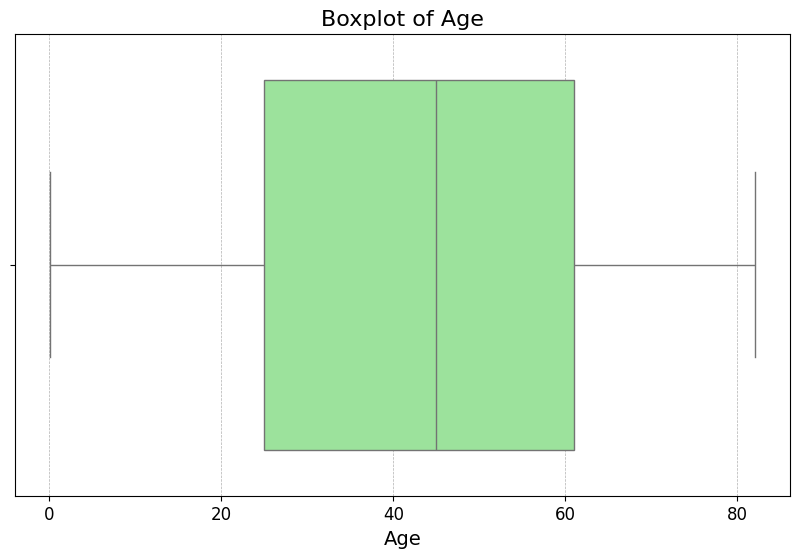

In [ ]:
# Plotting the boxplot for 'age'
plt.figure(figsize=(10, 6))  # Set the figure size
sns.boxplot(data=stroke_data, x='age', color='lightgreen')

# Customizing the plot
plt.title('Boxplot of Age', fontsize=16)  # Add a title
plt.xlabel('Age', fontsize=14)  # Label for the x-axis
plt.grid(True, which='both', linestyle='--', linewidth=0.5, axis='x')  # Optional grid
plt.xticks(fontsize=12)  # Customize tick size for the x-axis

plt.show()

* The Age parameter values does not have any outliers
* And has a normal distribution

### AVERAGE GLUCOSE LEVEL ANALYSIS

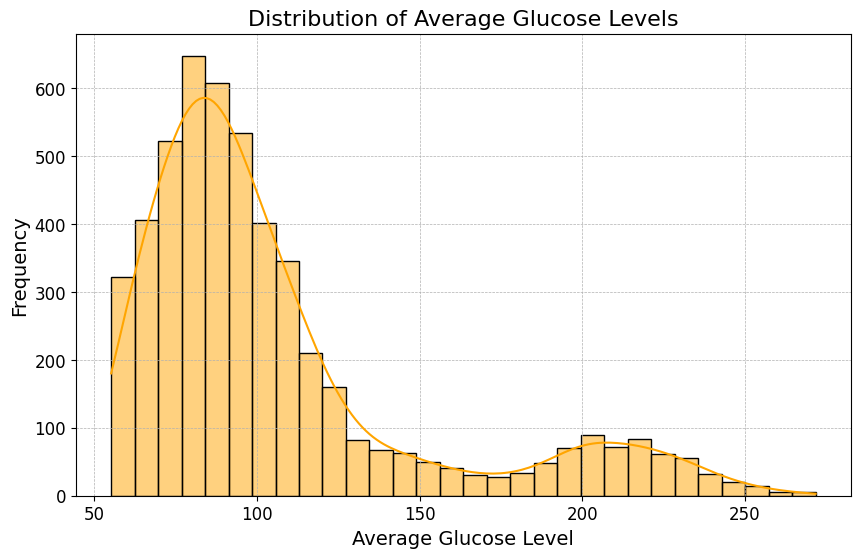

In [ ]:
# Plotting the histogram for the 'avg_glucose_level' column
plt.figure(figsize=(10, 6))  # Set the figure size
sns.histplot(data=stroke_data, x='avg_glucose_level', kde=True, bins=30, color='orange')

# Customizing the plot
plt.title('Distribution of Average Glucose Levels', fontsize=16)  # Add a title
plt.xlabel('Average Glucose Level', fontsize=14)  # Label for the x-axis
plt.ylabel('Frequency', fontsize=14)  # Label for the y-axis
plt.grid(True, which='both', linestyle='--', linewidth=0.5)  # Optional grid
plt.xticks(fontsize=12)  # Customize tick size for the x-axis
plt.yticks(fontsize=12)  # Customize tick size for the y-axis

plt.show()

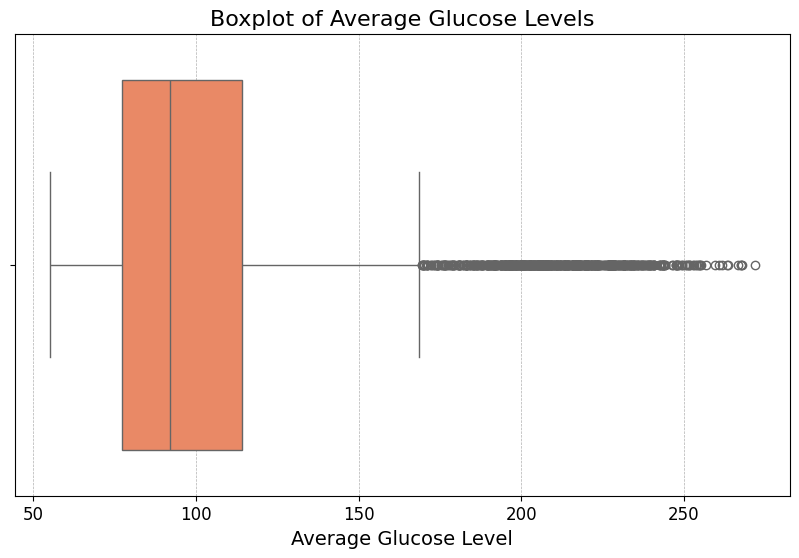

In [ ]:
# Plotting the boxplot for 'avg_glucose_level'
plt.figure(figsize=(10, 6))
sns.boxplot(data=stroke_data, x='avg_glucose_level', color='coral')

# Customizing the plot
plt.title('Boxplot of Average Glucose Levels', fontsize=16)
plt.xlabel('Average Glucose Level', fontsize=14)
plt.grid(True, which='both', linestyle='--', linewidth=0.5, axis='x')
plt.xticks(fontsize=12)

plt.show()

In [ ]:
# Finding the count of outliers based on those instances which are out of iqr
Q1 = stroke_data['avg_glucose_level'].quantile(0.25)
Q3 = stroke_data['avg_glucose_level'].quantile(0.75)
IQR = Q3 - Q1

# Identification des valeurs aberrantes
data = (stroke_data['avg_glucose_level'] < (Q1 - 1.5 * IQR)) | (stroke_data['avg_glucose_level'] > (Q3 + 1.5 * IQR))
print("Number of outliers in Average Glucose Levels : ", data.sum())

Number of outliers in Average Glucose Levels :  627


* Total outliers in avg_glucose_level : 627
* Total non-outliers in avg_glucose_level : 4483

### heart_disease Analysis

In [ ]:
# Value count of heart disease attribute
stroke_data['heart_disease'].value_counts()

,count
heart_disease,
0,4834
1,276


* This data reflects that around **94.6 %** of the total population or list of people are free from Heart_disease and only **5.4 %** are having **heart_disease**

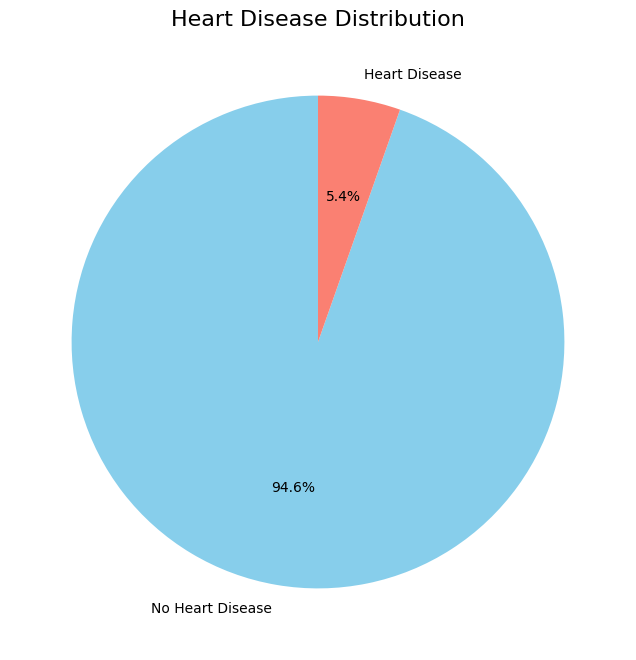

In [ ]:
# Plotting the pie chart for 'heart_disease'
stroke_data['heart_disease'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',  # Display percentages
    colors=['skyblue', 'salmon'],  # Customize colors
    startangle=90,  # Start the pie chart at 90 degrees
    figsize=(8, 8),  # Set the figure size
    labels=['No Heart Disease', 'Heart Disease']  # Add meaningful labels
)

# Customizing the plot
plt.title('Heart Disease Distribution', fontsize=16)
plt.ylabel('')  # Remove the default ylabel for cleaner visualization

plt.show()

### ever_married Analysis with Values

In [ ]:
# Value count of evver married attribute
stroke_data['ever_married'].value_counts()

,count
ever_married,
Yes,3353
No,1757


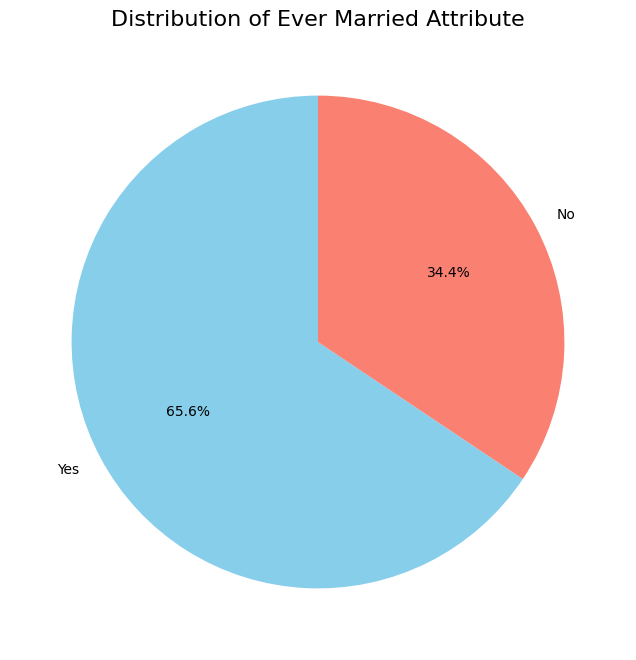

In [ ]:
# Plotting the pie chart for 'ever_married'
stroke_data['ever_married'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',  # Display percentages
    colors=['skyblue', 'salmon'],  # Custom colors for the slices
    startangle=90,  # Start the pie chart at 90 degrees
    figsize=(8, 8),  # Set the figure size
    labels=['Yes', 'No']  # Provide meaningful labels
)

# Customizing the plot
plt.title('Distribution of Ever Married Attribute', fontsize=16)
plt.ylabel('')  # Remove the default ylabel for a cleaner visualization

# Show the plot
plt.show()


## Cross Analysis - all the attribute compared with target attibute

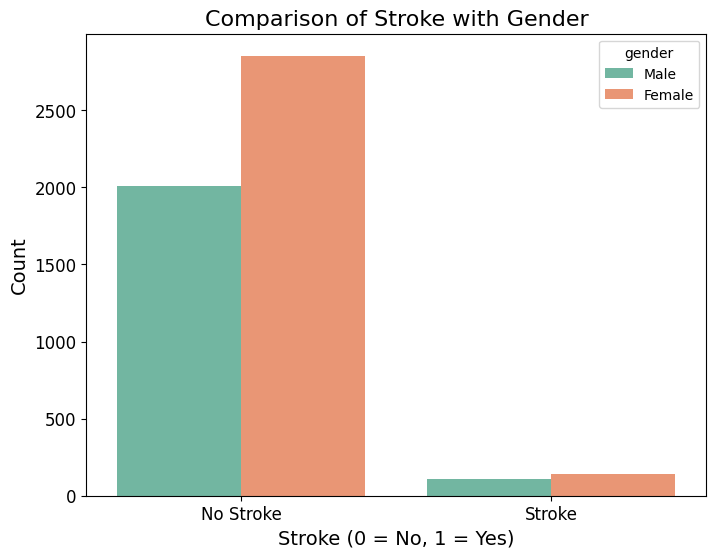

In [ ]:
# Plotting the count plot for 'stroke' compared with 'gender'
plt.figure(figsize=(8, 6))  # Set the figure size
sns.countplot(x='stroke', hue='gender', data=stroke_data, palette='Set2')

# Customizing the plot
plt.title('Comparison of Stroke with Gender', fontsize=16)
plt.xlabel('Stroke (0 = No, 1 = Yes)', fontsize=14)  # Label for x-axis
plt.ylabel('Count', fontsize=14)  # Label for y-axis
plt.xticks(ticks=[0, 1], labels=['No Stroke', 'Stroke'], fontsize=12)  # Custom x-axis labels
plt.yticks(fontsize=12)  # Customize tick size for the y-axis


plt.show()

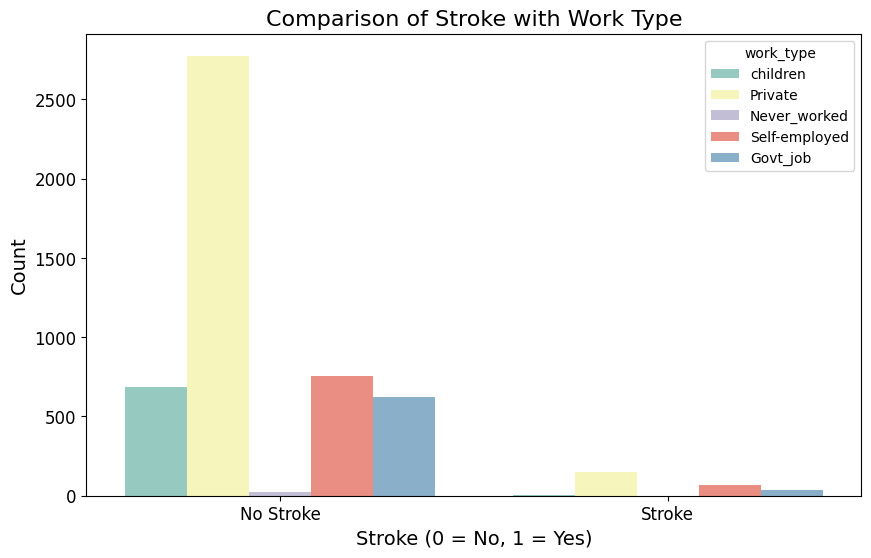

In [ ]:
# Plotting the count plot for 'stroke' compared with 'work_type'
plt.figure(figsize=(10, 6))  # Set the figure size
sns.countplot(x='stroke', hue='work_type', data=stroke_data, palette='Set3')

# Customizing the plot
plt.title('Comparison of Stroke with Work Type', fontsize=16)
plt.xlabel('Stroke (0 = No, 1 = Yes)', fontsize=14)  # Label for x-axis
plt.ylabel('Count', fontsize=14)  # Label for y-axis
plt.xticks(ticks=[0, 1], labels=['No Stroke', 'Stroke'], fontsize=12)  # Custom x-axis labels
plt.yticks(fontsize=12)  # Customize tick size for the y-axis

plt.show()

* Based on this comparison we see in the provided dataset that people who never worked never got a heart attack and the people who are privetly employed got more strokes

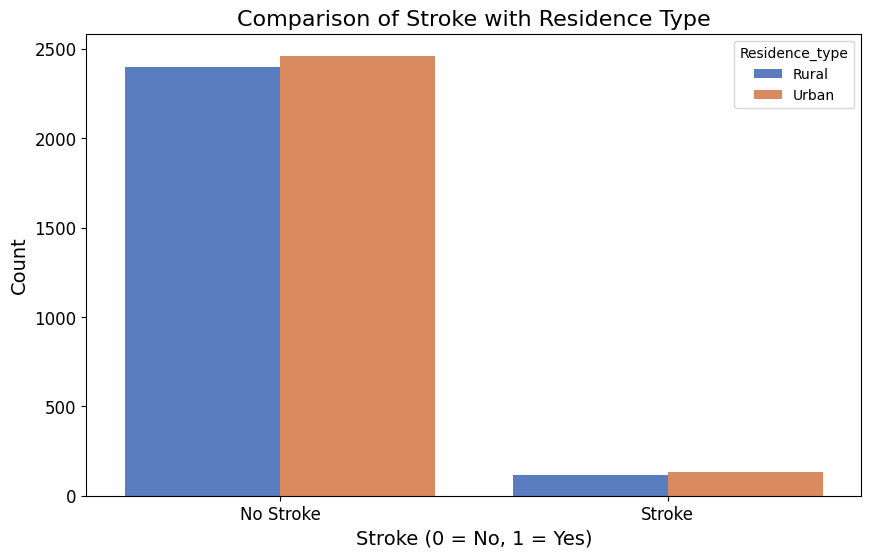

In [ ]:
# Plotting the count plot for 'stroke' compared with 'Residence_type'
plt.figure(figsize=(10, 6))  # Set the figure size
sns.countplot(x='stroke', hue='Residence_type', data=stroke_data, palette='muted')

# Customizing the plot
plt.title('Comparison of Stroke with Residence Type', fontsize=16)
plt.xlabel('Stroke (0 = No, 1 = Yes)', fontsize=14)  # Label for x-axis
plt.ylabel('Count', fontsize=14)  # Label for y-axis
plt.xticks(ticks=[0, 1], labels=['No Stroke', 'Stroke'], fontsize=12)  # Custom x-axis labels
plt.yticks(fontsize=12)  # Customize tick size for the y-axis

plt.show()

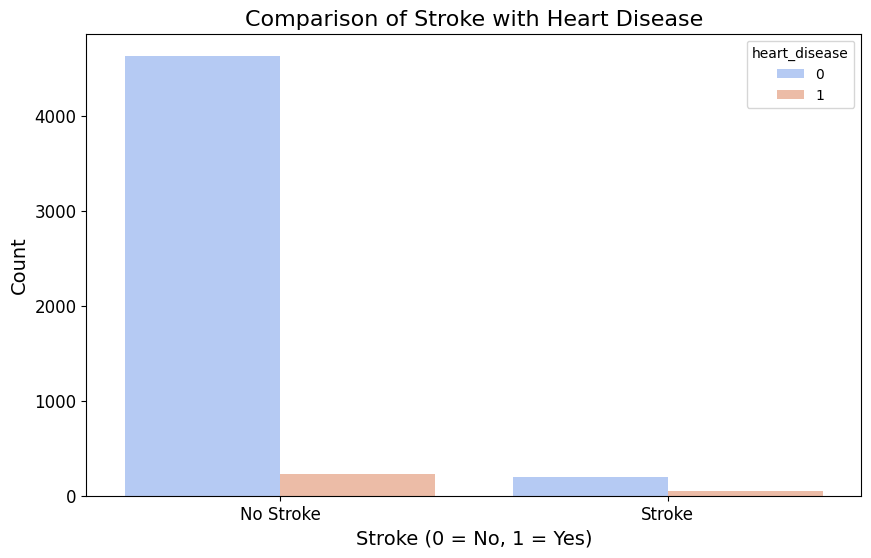

In [ ]:
# Plotting the count plot for 'stroke' compared with 'heart_disease'
plt.figure(figsize=(10, 6))  # Set the figure size
sns.countplot(x='stroke', hue='heart_disease', data=stroke_data, palette='coolwarm')

# Customizing the plot
plt.title('Comparison of Stroke with Heart Disease', fontsize=16)
plt.xlabel('Stroke (0 = No, 1 = Yes)', fontsize=14)  # Label for x-axis
plt.ylabel('Count', fontsize=14)  # Label for y-axis
plt.xticks(ticks=[0, 1], labels=['No Stroke', 'Stroke'], fontsize=12)  # Custom x-axis labels
plt.yticks(fontsize=12)  # Customize tick size for the y-axis

plt.show()

* This plotting shows that the number of "people with Strokes but no heart disease" is approximately 6 to 8 times the number of "people with Strokes and also heart disease". This shows most of the people with no heart disease are suffering with Strokes compared to the once who have Heart Disease.

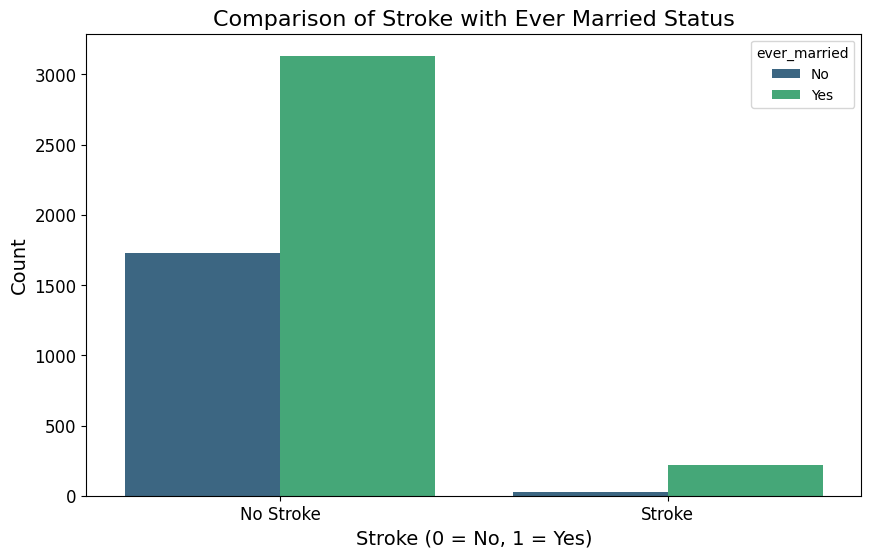

In [ ]:
# Plotting the count plot for 'stroke' compared with 'ever_married'
plt.figure(figsize=(10, 6))  # Set the figure size
sns.countplot(x='stroke', hue='ever_married', data=stroke_data, palette='viridis')

# Customizing the plot
plt.title('Comparison of Stroke with Ever Married Status', fontsize=16)
plt.xlabel('Stroke (0 = No, 1 = Yes)', fontsize=14)  # Label for x-axis
plt.ylabel('Count', fontsize=14)  # Label for y-axis
plt.xticks(ticks=[0, 1], labels=['No Stroke', 'Stroke'], fontsize=12)  # Custom x-axis labels
plt.yticks(fontsize=12)  # Customize tick size for the y-axis

plt.show()

* This plotting shows that the number of "Married people with Strokes" is approximately 10 to 12 times the number of "Unmarried people with Strokes".
* This shows most of the Married people got Strokes compared to Unmarried people.

## Feature Engineering

## Encoding

In [ ]:
# Creating Dummy Variables for Numeric-Binary Attributes
categorical_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
label_encoders = {col: LabelEncoder() for col in categorical_cols}
for col in categorical_cols:
    stroke_data[col] = label_encoders[col].fit_transform(stroke_data[col])


In [ ]:
stroke_data.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,67.0,0,1,1,2,1,228.69,36.6,1,1
1,0,61.0,0,0,1,3,0,202.21,28.1,2,1
2,1,80.0,0,1,1,2,0,105.92,32.5,2,1
3,0,49.0,0,0,1,2,1,171.23,34.4,3,1
4,0,79.0,1,0,1,3,0,174.12,24.0,2,1


## Correlation matrix

<Axes: >

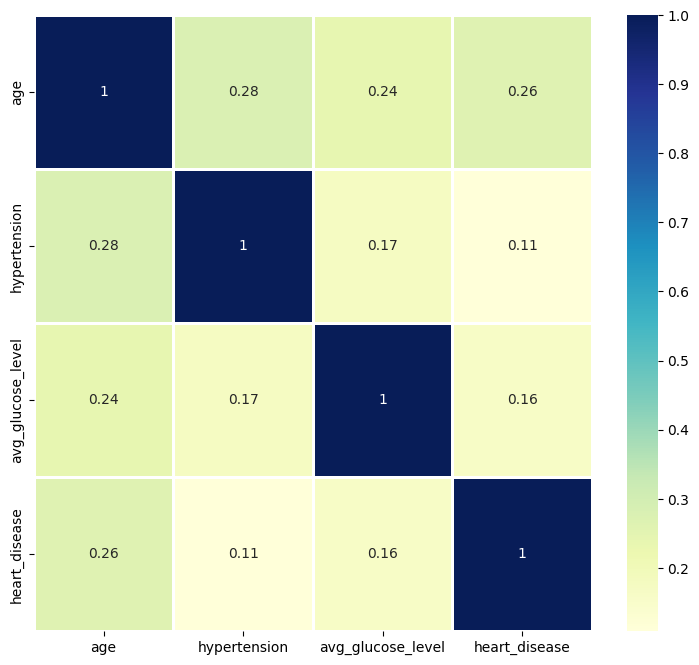

In [ ]:
# Correlation matrix between the attributes in the dataset to find if any attributes are correlated
corrmat=stroke_data[["age","hypertension","avg_glucose_level","heart_disease"]].corr()
f,ax=plt.subplots(figsize=(9,8))
sns.heatmap(corrmat,ax=ax,cmap="YlGnBu",linewidth=0.8,annot=True)

## Scaling

In [ ]:
# Since the numeric attributes in the dataset is in different ranges and three are outliers persent we are usign a scaler to get all the values
#into the same range.
# Standardiser les colonnes numériques
numeric_cols = ['age', 'avg_glucose_level', 'bmi']
scaler = StandardScaler()
stroke_data[numeric_cols] = scaler.fit_transform(stroke_data[numeric_cols])

In [ ]:
stroke_data.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


# **test-train split**

In [ ]:
# Since our Dataset is highly undersampled (based on target instances) we are going to perform a over sampling method to have equal representation of both the target classes
#Séparer les données
X = stroke_data.drop(columns=['stroke'])
y = stroke_data['stroke']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

In [ ]:
print("Avant SMOTE :", Counter(y_train))
print("Après SMOTE :", Counter(y_train_balanced))

Avant SMOTE : Counter({0: 3889, 1: 199})
Après SMOTE : Counter({0: 3889, 1: 3889})


## **Model choice (Paycaret )**

In [ ]:
!pip install pycaret

# ***Training Model***

### Random Forest Model

In [ ]:
# Create the classifier object
rf_clf = RandomForestClassifier(    random_state=0,
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='sqrt'
)
# Train the model using the training sets
rf_clf.fit(X_train_balanced, y_train_balanced)

# performing predictions on the test dataset
y_pred_rf = rf_clf.predict(X_test)

# Printing accuracy of the model
y_pred_train = rf_clf.predict(X_train)
print('Training Accuracy:', accuracy_score(y_train, y_pred_train))

In [ ]:
print('Test Accuracy:', accuracy_score(y_test, y_pred_rf))

## Cross-Validation

In [ ]:
# Performing k fold cross validation using 5 splits
kfold_kridge = model_selection.KFold(n_splits=5, shuffle=True)
results_kfold = model_selection.cross_val_score(rf_clf, X, y, cv=kfold_kridge)
print("Accuracy: ", results_kfold.mean()*100)
print(results_kfold)

## confusion matrix

In [ ]:
conf_matrix = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=rf_clf.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for RabdomForestClassifier")
plt.show()


* Training Accuracy (0.8496) and Test Accuracy (0.8023), These values are relatively close to each other, which typically indicates there is no obvious sign of overfitting.
* The fact that the Cross-Validation Accuracy (95.06% average) results are consistent and high indicates good generalization ability.

### XGBoost Model

In [ ]:
# Create the classifier object
xgboost_clf = XGBClassifier()

# Train the model using the training sets
xgboost_clf.fit(X_train_balanced, y_train_balanced)

# performing predictions on the test dataset
y_pred_xgboost = xgboost_clf.predict(X_test)

# Printing accuracy of the model

y_pred_train = xgboost_clf.predict(X_train)
print('Training Accuracy:', accuracy_score(y_train, y_pred_train))

In [ ]:
print('Test Accuracy:', accuracy_score(y_test, y_pred_xgboost))

## Cross-Validation

In [ ]:
k_folds = 5  # Number of folds
kfold = KFold(n_splits=k_folds, shuffle=True, random_state=42)

# Perform cross-validation
cv_results = cross_val_score(xgboost_clf, X, y, cv=kfold, scoring='accuracy')
print(f"Cross-Validation Accuracy Scores: {cv_results}")
print(f"Mean Accuracy: {cv_results.mean():.4f}")

* Training Accuracy (0.9897) and Test Accuracy (0.9041), These values are relatively close to each other, which typically indicates there is no obvious sign of overfitting.
* The fact that the Cross-Validation Accuracy (94% average) results are consistent and high indicates good generalization ability.

## confusion_matrix

In [ ]:
conf_matrix = confusion_matrix(y_test, y_pred_rf)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=rf_clf.classes_)
disp.plot(cmap=plt.cm.Greens)
plt.title("Confusion Matrix for XGBClassifier")
plt.show()


### Compare Model Performance

In [ ]:
# Comparaison des modèles
model_names = ['Random Forest', 'XGBoost']
accuracies = [accuracy_score(y_test, y_pred_rf), accuracy_score(y_test, y_pred_xgboost)]

plt.figure(figsize=(8, 6))
sns.barplot(x=model_names, y=accuracies)
plt.title('Comparison of Model Accuracies')
plt.ylabel('Accuracy')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.show()


* The fact that XGBoost has a higher accuracy indicates that it has better captured the relationships or structures in the data. This may be due to its adaptive approach (boosting) and better handling of errors or imbalances in the data.